Tomasz Lepszy, *475898*

# Meeting 2 — Text-to-image generation

**Where things stand**

| Step | Status | Where |
| --- | --- | --- |
| Generate 6 pools (base + 5 one-setting changes) on a Colab T4 | ✅ done | [colab/m2_train.ipynb](../colab/m2_train.ipynb) |
| Train 6 runs × 5 seeds | ✅ done | [colab/m2_train.ipynb](../colab/m2_train.ipynb) |
| Contact sheets and failure types | ✅ done | section 2 |
| Validation analysis | ✅ done | sections 4, 6.1 |
| Pick the pool to test | ✅ `m2-base` (set the same `POOL_RUN` in Colab) | sections 5.1, 6.1 |
| Test the picked pool once | ⬜ | [colab/m2_test.ipynb](../colab/m2_test.ipynb), section 5.2 |
| Test interpretation | ⬜ | section 6.2 |

**Contents**
1. Problem: where Meeting 1 left off, the question, the expectations
2. The pools: settings, generation log, contact sheets, failure types
3. What was done: training and the helpers
4. Validation results: all pools, each setting, the other breeds, the hard Maus
5. Picking the pool to test, and the test results
6. Interpretation, conclusion, limitations

This notebook only **reads and analyses**. Generation, training and testing need a GPU and live in `colab/` (shared code: `colab/colab_tools.py`). Run it locally after `git pull`. The generated images themselves are on Google Drive, not in git: everything here is drawn from the manifests, `pool.json` files, contact sheets and `runs/`.

### Setup
Moves to the repository root, makes `synthdata` importable and checks that Oxford-IIIT Pet is in `./data`.

In [25]:
import csv
import itertools
import json
import os
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

here = Path.cwd()
os.chdir(next(p for p in [here, *here.parents] if (p / "pyproject.toml").exists()))
if str(Path("src").resolve()) not in sys.path:
    sys.path.insert(0, str(Path("src").resolve()))

from synthdata import data
from synthdata.config import CLASSES, TARGET

data.download()  # skipped when ./data is already extracted
split = pd.DataFrame([p.__dict__ for p in data.load_split()])
missing = [i for i in split["image"] if not (data.image_path(i).exists() and data.trimap_path(i).exists())]
assert not missing, f"{len(missing)} photos missing from ./data, e.g. {missing[0]}"

ROOT = Path(".")
RUNS_DIR = ROOT / "runs"
POOLS_DIR = ROOT / "pools"
EVIDENCE_DIR = ROOT / "evidence"
EVIDENCE_DIR.mkdir(exist_ok=True)

BASELINES = ["m1-real", "m1-oversample", "m1-augment-strong"]  # Meeting 1, all tested
POOL_RUNS = ["m2-base", "m2-guidance-2", "m2-guidance-15", "m2-steps-10", "m2-prompt-simple", "m2-sdxl-turbo"]
RUN_NAMES = BASELINES + POOL_RUNS
COLORS = {
    "m1-real": "tab:gray", "m1-oversample": "tab:blue", "m1-augment-strong": "tab:red",
    "m2-base": "black", "m2-guidance-2": "tab:green", "m2-guidance-15": "tab:olive",
    "m2-steps-10": "tab:purple", "m2-prompt-simple": "tab:brown", "m2-sdxl-turbo": "tab:cyan",
}
# the one setting each pool changes, as tagged in synth-train
CHANGED = {"m2-base": "–", "m2-guidance-2": "guidance 7.5 → 2", "m2-guidance-15": "guidance 7.5 → 15",
           "m2-steps-10": "steps 30 → 10", "m2-prompt-simple": "4 prompts → 1 simple prompt",
           "m2-sdxl-turbo": "model sd15 → sdxl-turbo"}
print(f"Ready: {Path.cwd()} | {len(split)} course photos")


def save(fig, name):
    """Save a figure to evidence/ and show it."""
    fig.savefig(EVIDENCE_DIR / name, dpi=160)
    plt.show()

PICK, RIVAL = "m2-base", "m2-guidance-2"  # the two candidates compared in section 6.1
LOOK = "background-color: #ffe08a; color: black"               # values the pick rests on
KEY = "background-color: #f4a259; color: black; font-weight: bold"  # the decisive value


def highlight(df, cells=(), key=(), precision=3):
    """Style a table: `cells` and `key` are lists of (row, column) to mark."""
    def styles(frame):
        out = pd.DataFrame("", index=frame.index, columns=frame.columns)
        for marks, style in [(cells, LOOK), (key, KEY)]:
            for row, col in marks:
                if row in out.index and col in out.columns:
                    out.loc[row, col] = style
        return out
    return df.style.apply(styles, axis=None).format(precision=precision)


def cells_of(rows, cols):
    return [(r, c) for r in rows for c in cols]


Ready: /Users/tomaszlepszy/Local/git/dane_syntetyczne | 905 course photos


## 1. Problem

### 1.1 Where Meeting 1 left off

The course question is unchanged: *can images made by diffusion models improve recognition of Egyptian Mau, an under-represented cat breed, without harming the other seven breeds?* Meeting 1 gave the bars that every synthetic pool is measured against (validation / **test**, mean over 5 seeds):

| Run | What the 55 extra Mau examples are | Mau recall val / **test** | Macro-F1 val / **test** |
| --- | --- | ---: | ---: |
| `m1-real` | none (15 Maus vs 70 per other breed) | 0.49 / **0.49** | 0.865 / **0.855** |
| `m1-oversample` | copies of the 15 photos | 0.69 / **0.70** | 0.894 / **0.882** |
| `m1-augment-strong` | strongly transformed copies | 0.78 / **0.73** | 0.903 / **0.885** |

Two bars matter here:
- **`m1-oversample`** is the bar for "*does a generated image add anything beyond balancing?*" A synthetic pool fixes the class prior just as copies do, so only the part above oversampling is due to the images being new.
- **`m1-augment-strong`** is the best real-data method, and the bar for "*is it worth running a diffusion model at all?*"

Meeting 1 also showed what is left: a handful of validation Maus that no model recognises (#15, #155, #131, plus #152 and #171 that only the strong recipe sometimes recovers), all Maus in views the 15 training photos don't contain. And the cost of every gain so far was more **Bengals called "Mau"**.

The setup is the same as in Meeting 1 (split, EfficientNet-B0, 8 epochs, 5 seeds, budget 55). The only change is where the 55 extra Mau examples come from: **images generated from a text prompt**, with no connection to the 15 photos.

### 1.2 Question and expectations

> **Do Egyptian Mau images generated from a text prompt help the classifier more than copies of the 15 real photos, and which generation settings make them useful?**

Behind it is the question Meeting 1 ended on: generated images are the first source of *new* cats, poses and scenes. If missing variety is what limits the balanced runs, text-to-image is the first method that can add it. But it can also add the wrong thing: a cat that is not a Mau, or a "generated look" the classifier learns instead of the breed.

What I expected before generating (from [meeting0.ipynb](meeting0.ipynb), sections 5.3 and 6, and `EXPERIMENTS.md`):

1. **Text-to-image is the riskiest method.** Asked for an "Egyptian Mau", the model may draw a generic spotted cat (Bengal-like) or a tabby. Such images could push Bengals to "Mau" without helping real Maus. **At best a small gain over oversampling.**
2. **Guidance** trades prompt adherence for variety: high guidance (15) saturates colours and narrows variety; low guidance (2) follows the prompt loosely, so fewer images will look like a Mau.
3. **Fewer steps** (10) mean sampler error and blur.
4. **One simple prompt** gives a narrower pool than four varied prompts (fewer poses and scenes).
5. **SDXL-Turbo** is distilled for sharp images in 4 steps: polished and less diverse.
6. **Bengal recall** is the number to watch.

### 1.3 How I want to solve it

One base pool and five pools that each change **one** of its settings. Each pool has 110 images; each training seed adds a different random 55 of them (`pools.draw()` with the seeded `rng`). Everything else (data split, model, epochs, seeds) is as in Meeting 1, so any difference between runs comes from the pool.

| Pool / run | Setting changed vs `m2-base` | Tag |
| --- | --- | --- |
| `m2-base` | – (SD 1.5, 30 steps, guidance 7.5, DPM-Solver, 4 prompts) | `setting=base` |
| `m2-guidance-2` | guidance 7.5 → **2** | `guidance=2` |
| `m2-guidance-15` | guidance 7.5 → **15** | `guidance=15` |
| `m2-steps-10` | steps 30 → **10** | `steps=10` |
| `m2-prompt-simple` | four varied prompts → **one simple prompt** | `prompt=simple` |
| `m2-sdxl-turbo` | model SD 1.5 → **SDXL-Turbo** | `model=sdxl-turbo` |

So four of the course's settings are tested: guidance (2, 7.5, 15), steps (10, 30), prompt and model. All pools use seed 1000 for image 0, so image *i* starts from the same noise in every SD 1.5 pool.

**The prompts** (image *i* uses prompt *i* mod 4). They describe the breed's features (silver or bronze coat, small dark spots, green eyes, the M on the forehead) and vary the pose, framing and scene on purpose, because Meeting 1's hard Maus are close-ups, lying cats, bronze cats and indoor scenes:

1. *Egyptian Mau cat, silver coat with small dark spots, sitting on a woven rug in daylight*
2. *Egyptian Mau cat lying on a fabric sofa, spotted silver fur, green eyes, indoor lighting*
3. *close-up of an Egyptian Mau cat face near a window, spotted forehead with M marking, natural light*
4. *bronze Egyptian Mau cat walking across a wooden floor, small spots, casual home setting*

The simple prompt is just *Egyptian Mau cat*. The **negative prompt**, the same for all pools, steers away from non-photos and from the spotted wild cats a Mau could be confused with: *drawing, painting, illustration, 3d render, cartoon, text, watermark, leopard, cheetah, jaguar, extra legs, deformed anatomy*.

**One caveat about "one setting":** SDXL-Turbo runs with its own defaults, 4 steps, guidance 0 and its default scheduler, because it is distilled for exactly those. At guidance 0 the negative prompt is not used at all. So `m2-sdxl-turbo` changes the whole generator, not one knob; it answers "*which model?*", not "*which setting?*".

## 2. The pools

### 2.1 Settings, as recorded in each `pool.json`

In [26]:
def pool_settings(name):
    return json.loads((POOLS_DIR / name / "pool.json").read_text())


settings_table = pd.DataFrame({
    name: {"model": s["model"], "scheduler": s["scheduler"], "steps": s["steps"], "guidance": s["guidance"],
           "prompts": len(s["prompts"]), "negative prompt": "yes" if s["negative_prompt"] else "no",
           "seed of image 0": s["seed"], "size": s["size"]}
    for name in POOL_RUNS for s in [pool_settings(name)]
}).T
base = settings_table.loc["m2-base"]
# highlight what differs from the base pool
settings_table.style.apply(lambda row: ["font-weight: bold; background: #fff3c4" if row[c] != base[c] else "" for c in row.index], axis=1)

,model,scheduler,steps,guidance,prompts,negative prompt,seed of image 0,size
m2-base,sd15,dpm,30,7.500000,4,yes,1000,512
m2-guidance-2,sd15,dpm,30,2.000000,4,yes,1000,512
m2-guidance-15,sd15,dpm,30,15.000000,4,yes,1000,512
m2-steps-10,sd15,dpm,10,7.500000,4,yes,1000,512
m2-prompt-simple,sd15,dpm,30,7.500000,1,yes,1000,512
m2-sdxl-turbo,sdxl-turbo,default,4,0.000000,4,yes,1000,512


### 2.2 Generation log

Every attempt has a line in the pool's `manifest.jsonl`: settings, seed, status, time and memory. Images flagged by Stable Diffusion's safety checker are kept as `safety_blocked` (a black image) and are never drawn for training.

In [27]:
def manifest(name):
    return pd.DataFrame([json.loads(line) for line in (POOLS_DIR / name / "manifest.jsonl").read_text().splitlines() if line])


manifests = {name: manifest(name) for name in POOL_RUNS}
pd.DataFrame({
    name: {"attempts": len(m), "ok": int((m["status"] == "ok").sum()),
           "safety blocked": int((m["status"] == "safety_blocked").sum()),
           "blocked ids": ", ".join(m.loc[m["status"] != "ok", "sample_id"].str[-4:]) or "–",
           "s / image": round(m["seconds"].mean(), 1), "peak VRAM (MB)": int(m["peak_vram_mb"].max()),
           "GPU": m["gpu"].iloc[0]}
    for name, m in manifests.items()
}).T

,attempts,ok,safety blocked,blocked ids,s / image,peak VRAM (MB),GPU
m2-base,110,110,0,–,5.3,3257,Tesla T4
m2-guidance-2,110,110,0,–,5.5,3257,Tesla T4
m2-guidance-15,110,110,0,–,5.5,3257,Tesla T4
m2-steps-10,110,108,2,"0064, 0092",2.0,3257,Tesla T4
m2-prompt-simple,110,109,1,0064,5.5,3257,Tesla T4
m2-sdxl-turbo,110,110,0,–,1.2,7663,Tesla T4


### 2.3 Contact sheets

The first 24 images of each pool (images #0–23 cycle through the four prompts, so every column of 4 is one prompt: columns 1 and 5 are prompt 1, columns 2 and 6 prompt 2, and so on in reading order). The same image number starts from the same noise in every SD 1.5 pool.

#### `m2-base` (base settings)

![m2-base contact sheet](../pools/m2-base/contact-sheet.jpg)

#### `m2-guidance-2` (guidance 7.5 → 2)

![m2-guidance-2 contact sheet](../pools/m2-guidance-2/contact-sheet.jpg)

#### `m2-guidance-15` (guidance 7.5 → 15)

![m2-guidance-15 contact sheet](../pools/m2-guidance-15/contact-sheet.jpg)

#### `m2-steps-10` (steps 30 → 10)

![m2-steps-10 contact sheet](../pools/m2-steps-10/contact-sheet.jpg)

#### `m2-prompt-simple` (4 prompts → 1 simple prompt)

![m2-prompt-simple contact sheet](../pools/m2-prompt-simple/contact-sheet.jpg)

#### `m2-sdxl-turbo` (model SD 1.5 → SDXL-Turbo)

![m2-sdxl-turbo contact sheet](../pools/m2-sdxl-turbo/contact-sheet.jpg)

### 2.4 Same seeds, one setting at a time

Images #0–3 (one per prompt) and #12–15 (the same prompts, other seeds) cut from the contact sheets. Each row is one pool; each column starts from the same noise. This is the clearest view of what each setting does.

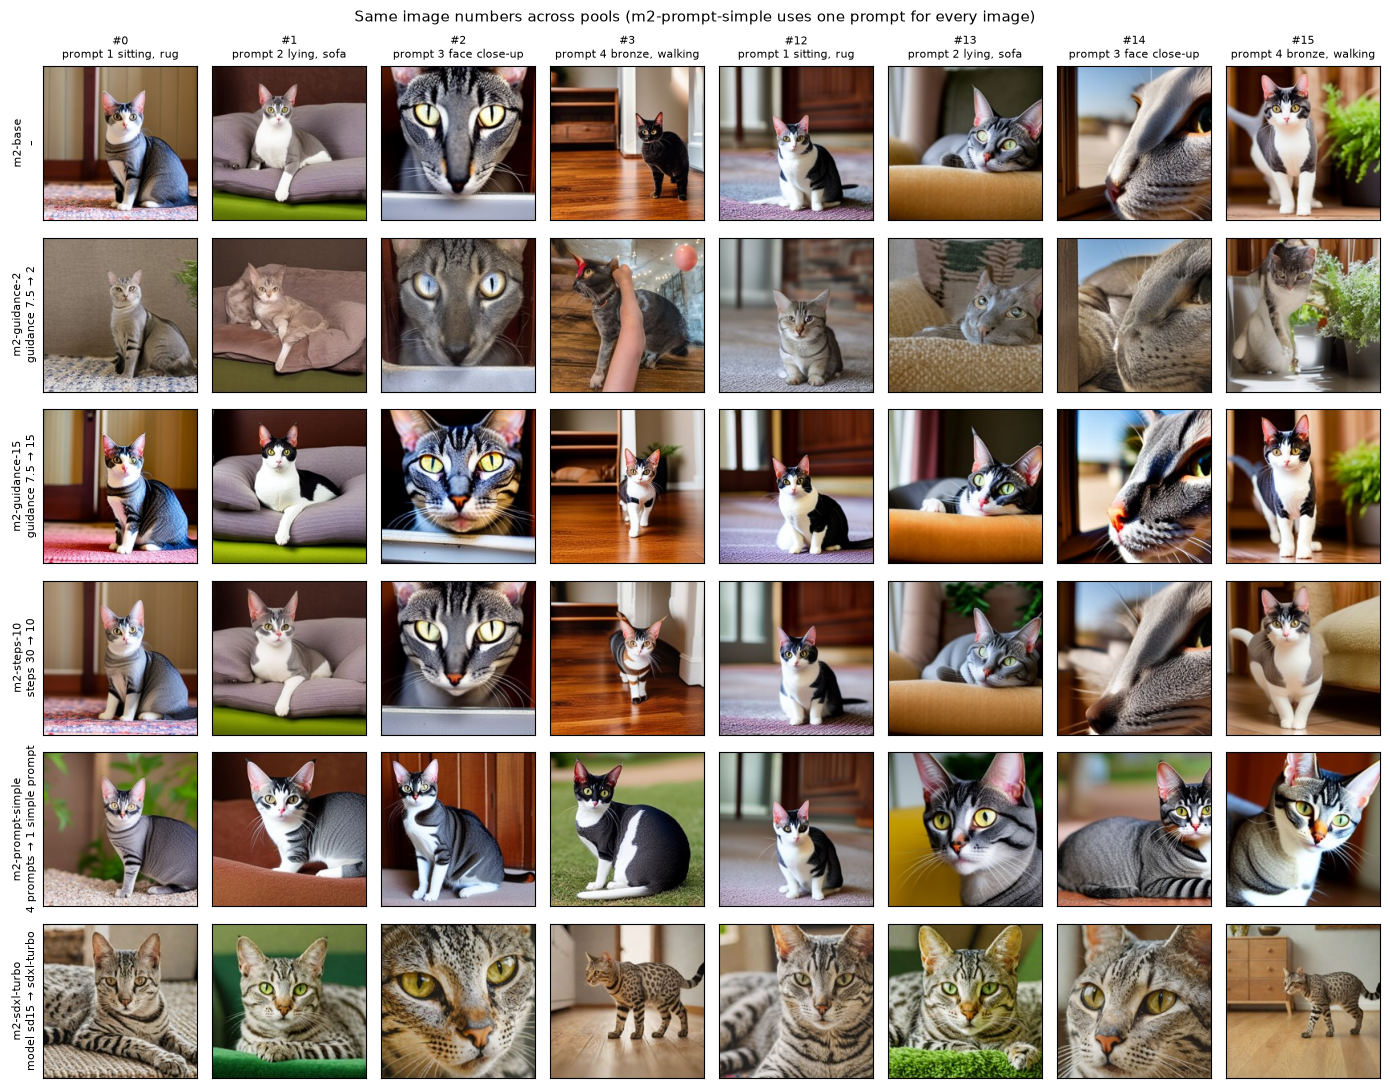

In [28]:
TILE, CAPTION, COLUMNS = 192, 18, 6  # layout of synthdata.sheets.contact_sheet for text-to-image pools


def tile(name, index):
    """Image `index` (0–23) of a pool, cut from its contact sheet."""
    sheet = Image.open(POOLS_DIR / name / "contact-sheet.jpg")
    x, y = (index % COLUMNS) * TILE, (index // COLUMNS) * (TILE + CAPTION)
    return sheet.crop((x, y, x + TILE, y + TILE))


SHOWN = [0, 1, 2, 3, 12, 13, 14, 15]
PROMPT_LABEL = ["1 sitting, rug", "2 lying, sofa", "3 face close-up", "4 bronze, walking"]
fig, axes = plt.subplots(len(POOL_RUNS), len(SHOWN), figsize=(1.75 * len(SHOWN), 1.85 * len(POOL_RUNS)))
for r, name in enumerate(POOL_RUNS):
    for c, index in enumerate(SHOWN):
        ax = axes[r, c]
        ax.imshow(tile(name, index))
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(f"#{index}\nprompt {PROMPT_LABEL[index % 4]}" if name != "m2-prompt-simple" else f"#{index}", fontsize=8)
        if c == 0:
            ax.set_ylabel(f"{name}\n{CHANGED[name]}", fontsize=8)
fig.suptitle("Same image numbers across pools (m2-prompt-simple uses one prompt for every image)", fontsize=11)
fig.tight_layout()
save(fig, "meeting2-pools-same-seeds.png")

### 2.5 Failure types

What I see in the contact sheets (24 of 110 images per pool), against what an Egyptian Mau looks like: a **silver, bronze or smoke** short-haired cat with **random small dark spots** on the body, a striped tail and legs, an **M on the forehead**, and green "gooseberry" eyes.


| Failure type | Where | Examples (image #) |
| --- | --- | --- |
| **Wrong breed: bicolour "tuxedo" cat** (grey or black back, white chest and legs) | SD 1.5, all settings; the most common SD 1.5 cat | base #1, #8, #12, #15, #20; simple prompt almost every image |
| **Wrong coat: striped tabby instead of spots** | SD 1.5, all settings | base #0, #5, #10, #16; guidance-2 #12, #16 |
| **"Bronze" becomes black** | prompt 4 in SD 1.5: no image shows a bronze cat | base #3, #23; guidance-15 #23 |
| **Leopard-like rosettes and striped legs** (Bengal / ocelot look, despite "leopard" in the negative prompt) | SDXL-Turbo | turbo #3, #7, #11, #19 |
| **Odd framing**: the cat inside a picture frame or box | SD 1.5, prompt 4 | base #7, #19 |
| **Over-cropped**: half a face, just an eye or a nose | prompt 3 ("close-up") | base #6, #14, #22 |
| **No cat, or a tiny cat lost in the room** | guidance 2 | guidance-2 #11, #19, #23 |
| **Extra content**: a human arm, two cats | guidance 2, simple prompt | guidance-2 #3; simple #8 |
| **Long-haired cat** | guidance 2 | guidance-2 #20 |
| **Over-saturated, harsh contrast** | guidance 15 | guidance-15 #18, #20 |
| **Repetition**: same pose, same backdrop | simple prompt (sitting, frontal, outdoors); SDXL-Turbo (same green cushion, same walking pose on a wooden floor, same portrait) | simple #0–#23; turbo #1, #5, #9, #17 and #7, #11, #19, #23 |
| **Safety-blocked** (black image, kept in the manifest, never trained on) | steps-10 (2), simple prompt (1) | steps-10 #64, #92; simple #64 |

What the settings do to the **same seeds** (2.4):

- **SD 1.5 doesn't know what an Egyptian Mau looks like.** With the base settings almost no image shows the random small spots of a Mau; it draws grey tabbies and bicolour cats with a Mau-ish face (large ears, green eyes). The breed words mostly turn into "grey cat with markings". The prompts do control the **scene and framing** well: rugs, sofas, wooden floors, close-ups, small cats in a room.
- **Guidance 15** keeps the composition of each base image and makes it harsher and more saturated. It doesn't make the cats more Mau-like.
- **Guidance 2** changes the composition: softer, more natural photos with more varied coats (brown and grey tabbies, a long-haired cat), and more failures (no cat, tiny cat, a human arm). It looks the most like ordinary snapshots.
- **10 steps** gives nearly the same images as 30: DPM-Solver++ has converged by 10 steps. Two images were blocked by the safety checker.
- **One simple prompt** gives the narrowest pool: almost every image is a frontal, sitting, bicolour cat outdoors.
- **SDXL-Turbo** is the only model that draws spotted silver cats with green eyes, the closest to a Mau by eye, but the spots are often Bengal-like rosettes, the legs and tail are boldly striped, and the pool repeats three compositions (portrait, lying on a green cushion, walking on a wooden floor).

The question for section 4 is whether "looks like a Mau" is what makes an image useful.

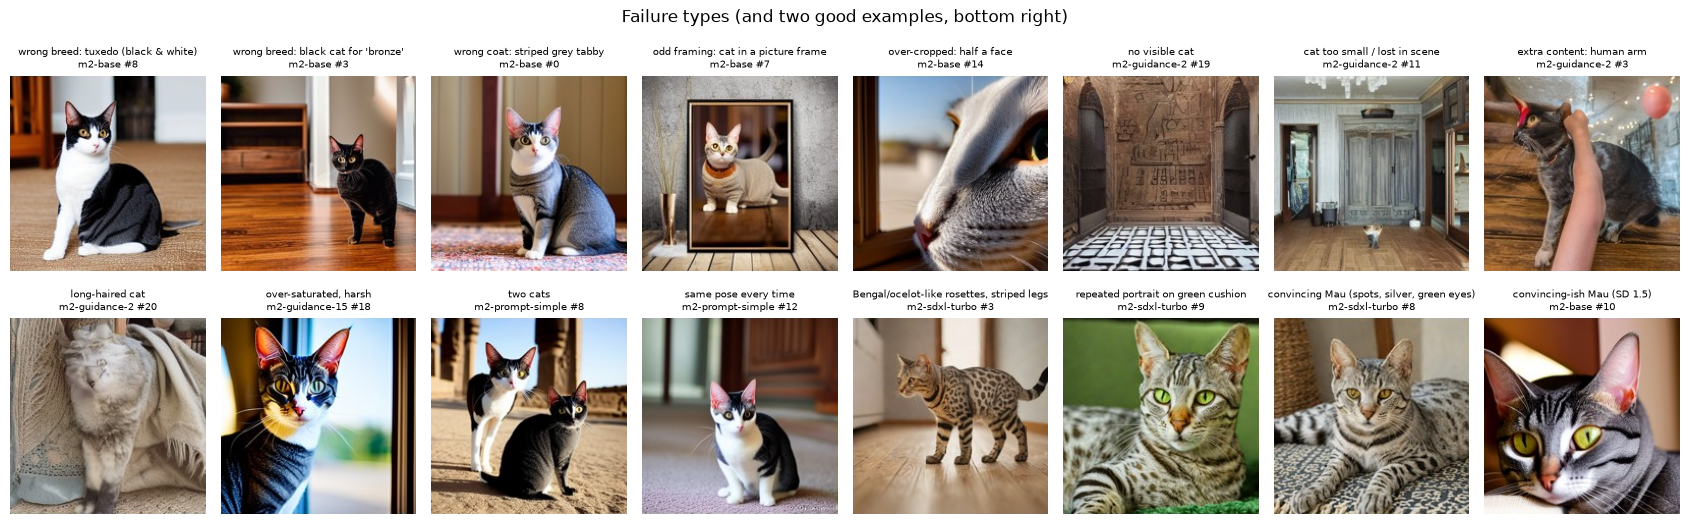

In [29]:
FAILURES = [  # (failure type, pool, image number) — picked from the contact sheets
    ("wrong breed: tuxedo (black & white)", "m2-base", 8),
    ("wrong breed: black cat for 'bronze'", "m2-base", 3),
    ("wrong coat: striped grey tabby", "m2-base", 0),
    ("odd framing: cat in a picture frame", "m2-base", 7),
    ("over-cropped: half a face", "m2-base", 14),
    ("no visible cat", "m2-guidance-2", 19),
    ("cat too small / lost in scene", "m2-guidance-2", 11),
    ("extra content: human arm", "m2-guidance-2", 3),
    ("long-haired cat", "m2-guidance-2", 20),
    ("over-saturated, harsh", "m2-guidance-15", 18),
    ("two cats", "m2-prompt-simple", 8),
    ("same pose every time", "m2-prompt-simple", 12),
    ("Bengal/ocelot-like rosettes, striped legs", "m2-sdxl-turbo", 3),
    ("repeated portrait on green cushion", "m2-sdxl-turbo", 9),
    ("convincing Mau (spots, silver, green eyes)", "m2-sdxl-turbo", 8),
    ("convincing-ish Mau (SD 1.5)", "m2-base", 10),
]
fig, axes = plt.subplots(2, 8, figsize=(17, 5.6))
for ax, (label, name, index) in zip(axes.ravel(), FAILURES):
    ax.imshow(tile(name, index))
    ax.set_title(f"{label}\n{name} #{index}", fontsize=7.5)
    ax.axis("off")
fig.suptitle("Failure types (and two good examples, bottom right)", fontsize=12)
fig.tight_layout()
save(fig, "meeting2-failure-types.png")

### 2.6 What each training seed actually got

Each seed draws its own 55 of the usable images. `run.json` lists them, so we can check that every seed got a balanced mix of the four prompts (a seed that drew mostly close-ups would be a different experiment).

In [30]:
rows = []
for name in POOL_RUNS:
    prompt_of = dict(zip(manifests[name]["sample_id"], manifests[name]["prompt"]))
    prompts = pool_settings(name)["prompts"]
    for k in range(5):
        added = json.loads((RUNS_DIR / name / f"seed-{k}" / "run.json").read_text())["added"]
        counts = Counter(prompts.index(prompt_of[s]) + 1 for s in added)
        rows.append({"run": name, "seed": k, "added": len(added),
                     **{f"prompt {p}": counts.get(p, 0) for p in range(1, len(prompts) + 1)}})
pd.DataFrame(rows).set_index(["run", "seed"]).fillna(0).astype(int)

added  prompt 1  prompt 2  prompt 3  prompt 4
run              seed                                               
m2-base          0        55        16        15        12        12
                 1        55        15        16        12        12
                 2        55        12        14        13        16
                 3        55        15        13        15        12
                 4        55        12        10        16        17
m2-guidance-2    0        55        16        15        12        12
                 1        55        15        16        12        12
                 2        55        12        14        13        16
                 3        55        15        13        15        12
                 4        55        12        10        16        17
m2-guidance-15   0        55        16        15        12        12
                 1        55        15        16        12        12
                 2        55        12        14        13        16
                 3        55        15        13        15        12
                 4        55        12        10        16        17
m2-steps-10      0        55        15        15         9        16
                 1        55        17        15        12        11
                 2        55        13        13        16        13
                 3        55        14        10        15        16
                 4        55        13        11        14        17
m2-prompt-simple 0        55        55         0         0         0
                 1        55        55         0         0         0
                 2        55        55         0         0         0
                 3        55        55         0         0         0
                 4        55        55         0         0         0
m2-sdxl-turbo    0        55        16        15        12        12
                 1        55        15        16        12        12
                 2        55        12        14        13        16
                 3        55        15        13        15        12
                 4        55        12        10        16        17

## 3. What was done

### 3.1 Generation and training
[colab/m2_train.ipynb](../colab/m2_train.ipynb) did everything on a Colab T4 GPU, one pool at a time:

```bash
synth-generate --name m2-base --device cuda --prompt "<prompt 1>" ... --prompt "<prompt 4>" --negative-prompt "<negative>"
synth-generate --name m2-guidance-2 ... --guidance 2          # and so on, one changed option per pool
synth-train --name m2-base --method synthetic --pool m2-base --device cuda --tag setting=base
```

After each pool it copied the images to Google Drive and pushed the manifest, `pool.json` and contact sheet to GitHub; after training, it checked every seed ran on `cuda`, copied `model.pt` to Drive and pushed `runs/`.

How the generated images enter training (`synthdata/train.py`): the 15 real Maus plus **55 generated images**, all labelled Egyptian Mau. Generated images are **not** passed through `augment()`; like every training image, they get only the pipeline's own random crop, flip and colour jitter (`TRAIN_TRANSFORM`). So the fair comparison for "are generated images better than copies" is `m1-oversample`, which also skips `augment()`.

### 3.2 Testing
Only the pool chosen on validation is tested, once, by [colab/m2_test.ipynb](../colab/m2_test.ipynb) (section 5). The three Meeting 1 baselines were tested in Meeting 1, and their `test-results.json` are reused.

### 3.3 Helpers for the analysis
The same helpers as in Meeting 1.

In [31]:
def load_runs(filename, run_names=None):
    """One row per (run, seed) from runs/<name>/<filename>."""
    records, missing = [], []
    for run_name in run_names or RUN_NAMES:
        path = RUNS_DIR / run_name / filename
        if not path.exists():
            missing.append(run_name)
            continue
        for seed in json.loads(path.read_text())["seeds"]:
            records.append({"run": run_name, "seed": seed["seed"],
                            "egyptian_mau_recall": seed["egyptian_mau_recall"],
                            "macro_f1": seed["macro_f1"], "accuracy": seed["accuracy"],
                            "bengal_recall": seed["recall"]["Bengal"]})
    if missing:
        print(f"No {filename} yet for:", ", ".join(missing))
    return pd.DataFrame(records)


def load_breed_recall(filename, run_names=None):
    """One row per (run, seed, breed) with that breed's recall."""
    rows = []
    for run_name in run_names or RUN_NAMES:
        for seed in json.loads((RUNS_DIR / run_name / filename).read_text())["seeds"]:
            for breed, value in seed["recall"].items():
                rows.append({"run": run_name, "seed": seed["seed"], "breed": breed, "recall": value})
    return pd.DataFrame(rows)


def summed_confusion(run_name, filename="metrics.json"):
    """Confusion matrix summed over the 5 seeds (rows = true, columns = predicted)."""
    total, names = None, None
    for k in range(5):
        m = json.loads((RUNS_DIR / run_name / f"seed-{k}" / filename).read_text())
        names = list(m["recall"])
        c = np.array(m["confusion"])
        total = c if total is None else total + c
    return total, names


def summarize(df, run_names=None):
    return (
        df.groupby("run", sort=False)
        .agg(seeds=("seed", "count"),
             recall_mean=("egyptian_mau_recall", "mean"), recall_std=("egyptian_mau_recall", "std"),
             recall_min=("egyptian_mau_recall", "min"), recall_max=("egyptian_mau_recall", "max"),
             macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
             bengal_recall=("bengal_recall", "mean"), accuracy_mean=("accuracy", "mean"))
        .reindex([r for r in run_names or RUN_NAMES if r in set(df["run"])])
        .round(3)
    )


def sign_flip_p(diffs):
    """Exact two-sided paired sign-flip (permutation) test over all 2^n sign patterns."""
    diffs = np.asarray(diffs, dtype=float)
    observed = abs(diffs.mean())
    signs = np.array(list(itertools.product([1, -1], repeat=len(diffs))))
    return float((np.abs((signs * diffs).mean(axis=1)) >= observed - 1e-12).mean())


def paired_tests(df, pairs, metrics=("egyptian_mau_recall", "macro_f1")):
    rows = []
    for metric in metrics:
        wide = df.pivot(index="seed", columns="run", values=metric)
        for a, b in pairs:
            d = wide[a] - wide[b]
            rows.append({"metric": metric, "comparison": f"{a} − {b}",
                         "mean diff": round(d.mean(), 3), "seeds better": int((d > 0).sum()),
                         "seeds equal": int((d == 0).sum()), "seeds worse": int((d < 0).sum()),
                         "p (sign-flip)": round(sign_flip_p(d), 3)})
    return pd.DataFrame(rows)


def plot_metric(df, metric, ylabel, title, run_names, ax, ylim=(0, 1.05)):
    """Dots = seeds, black bar = mean ± std."""
    for position, run_name in enumerate(run_names):
        values = df.loc[df["run"] == run_name, metric]
        ax.scatter([position] * len(values), values, alpha=0.8, color=COLORS[run_name],
                   label="individual seed" if position == 0 else None)
        ax.errorbar(position, values.mean(), yerr=values.std(ddof=1), fmt="_", color="black",
                    capsize=5, markersize=18, linewidth=2, label="mean ± std" if position == 0 else None)
    ax.set_xticks(range(len(run_names)), run_names, rotation=25, ha="right")
    ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="lower right")


def mau_error_table(run_names):
    """Mau row and column of the 5-seed summed confusion matrices."""
    rows = []
    for run_name in run_names:
        matrix, names = summed_confusion(run_name)
        mau = names.index(TARGET)
        for j, name in enumerate(names):
            rows.append({"breed": name, "run": run_name,
                         "Mau predicted as": matrix[mau, j], "predicted as Mau": matrix[j, mau]})
    return pd.DataFrame(rows).pivot(index="breed", columns="run", values=["Mau predicted as", "predicted as Mau"]).reindex(
        columns=pd.MultiIndex.from_product([["Mau predicted as", "predicted as Mau"], run_names]))

## 4. Validation results

This section reports numbers; they are interpreted in section 6.1. 20 validation photos per breed, so one Mau photo = 0.05 recall. The three Meeting 1 baselines are shown alongside.

#### Per-seed results

In [32]:
results = load_runs("results.json")
per_seed_recall = results.pivot(index="seed", columns="run", values="egyptian_mau_recall")[RUN_NAMES]
# the two candidates are equal on seeds 0-3; they differ only on seed 4
highlight(per_seed_recall, cells=cells_of(range(5), [PICK, RIVAL]), key=[(4, PICK), (4, RIVAL)], precision=2)

run,m1-real,m1-oversample,m1-augment-strong,m2-base,m2-guidance-2,m2-guidance-15,m2-steps-10,m2-prompt-simple,m2-sdxl-turbo
seed,,,,,,,,,
0,0.45,0.70,0.80,0.75,0.75,0.70,0.75,0.70,0.80
1,0.50,0.60,0.75,0.80,0.80,0.60,0.80,0.70,0.65
2,0.45,0.65,0.75,0.75,0.75,0.60,0.70,0.65,0.70
3,0.45,0.75,0.80,0.80,0.80,0.70,0.80,0.70,0.75
4,0.60,0.75,0.80,0.80,0.85,0.85,0.80,0.85,0.75


In [33]:
results.pivot(index="seed", columns="run", values="macro_f1")[RUN_NAMES].round(3)

run,m1-real,m1-oversample,m1-augment-strong,m2-base,m2-guidance-2,m2-guidance-15,m2-steps-10,m2-prompt-simple,m2-sdxl-turbo
seed,,,,,,,,,
0,0.860,0.911,0.912,0.905,0.912,0.898,0.905,0.898,0.912
1,0.869,0.859,0.880,0.894,0.881,0.872,0.894,0.887,0.854
2,0.861,0.898,0.899,0.912,0.917,0.890,0.911,0.898,0.911
3,0.855,0.906,0.918,0.906,0.912,0.898,0.912,0.899,0.905
4,0.877,0.899,0.906,0.912,0.906,0.919,0.906,0.912,0.887


#### Summary across seeds
`vs_oversample` and `vs_strong` are the differences of the means from `m1-oversample` and `m1-augment-strong`.

In [34]:
summary = summarize(results)
for ref, label in [("m1-oversample", "oversample"), ("m1-augment-strong", "strong")]:
    summary[f"recall_vs_{label}"] = (summary["recall_mean"] - summary.loc[ref, "recall_mean"]).round(3)
    summary[f"macro_f1_vs_{label}"] = (summary["macro_f1_mean"] - summary.loc[ref, "macro_f1_mean"]).round(3)
summary.insert(0, "changed", [CHANGED.get(r, "Meeting 1") for r in summary.index])
highlight(summary,
          cells=cells_of([PICK, RIVAL], ["recall_mean", "recall_std", "macro_f1_mean", "macro_f1_std"]),
          key=cells_of([PICK, RIVAL], ["bengal_recall"]))

,changed,seeds,recall_mean,recall_std,recall_min,recall_max,macro_f1_mean,macro_f1_std,bengal_recall,accuracy_mean,recall_vs_oversample,macro_f1_vs_oversample,recall_vs_strong,macro_f1_vs_strong
run,,,,,,,,,,,,,,
m1-real,Meeting 1,5,0.490,0.065,0.450,0.600,0.865,0.009,0.830,0.871,-0.200,-0.029,-0.290,-0.038
m1-oversample,Meeting 1,5,0.690,0.065,0.600,0.750,0.894,0.020,0.820,0.896,0.000,0.000,-0.090,-0.009
m1-augment-strong,Meeting 1,5,0.780,0.027,0.750,0.800,0.903,0.015,0.790,0.904,0.090,0.009,0.000,0.000
m2-base,–,5,0.780,0.027,0.750,0.800,0.906,0.007,0.850,0.906,0.090,0.012,0.000,0.003
m2-guidance-2,guidance 7.5 → 2,5,0.790,0.042,0.750,0.850,0.906,0.014,0.810,0.906,0.100,0.012,0.010,0.003
m2-guidance-15,guidance 7.5 → 15,5,0.690,0.102,0.600,0.850,0.896,0.017,0.850,0.898,0.000,0.002,-0.090,-0.007
m2-steps-10,steps 30 → 10,5,0.770,0.045,0.700,0.800,0.905,0.007,0.850,0.906,0.080,0.011,-0.010,0.002
m2-prompt-simple,4 prompts → 1 simple prompt,5,0.720,0.076,0.650,0.850,0.899,0.009,0.840,0.900,0.030,0.005,-0.060,-0.004
m2-sdxl-turbo,model sd15 → sdxl-turbo,5,0.730,0.057,0.650,0.800,0.894,0.025,0.800,0.895,0.040,0.000,-0.050,-0.009


#### Egyptian Mau recall, macro-F1 and Bengal recall
Each dot is one seed; the black bar is mean ± 1 std over the 5 seeds. The dashed lines are the means of `m1-oversample` (blue) and `m1-augment-strong` (red).

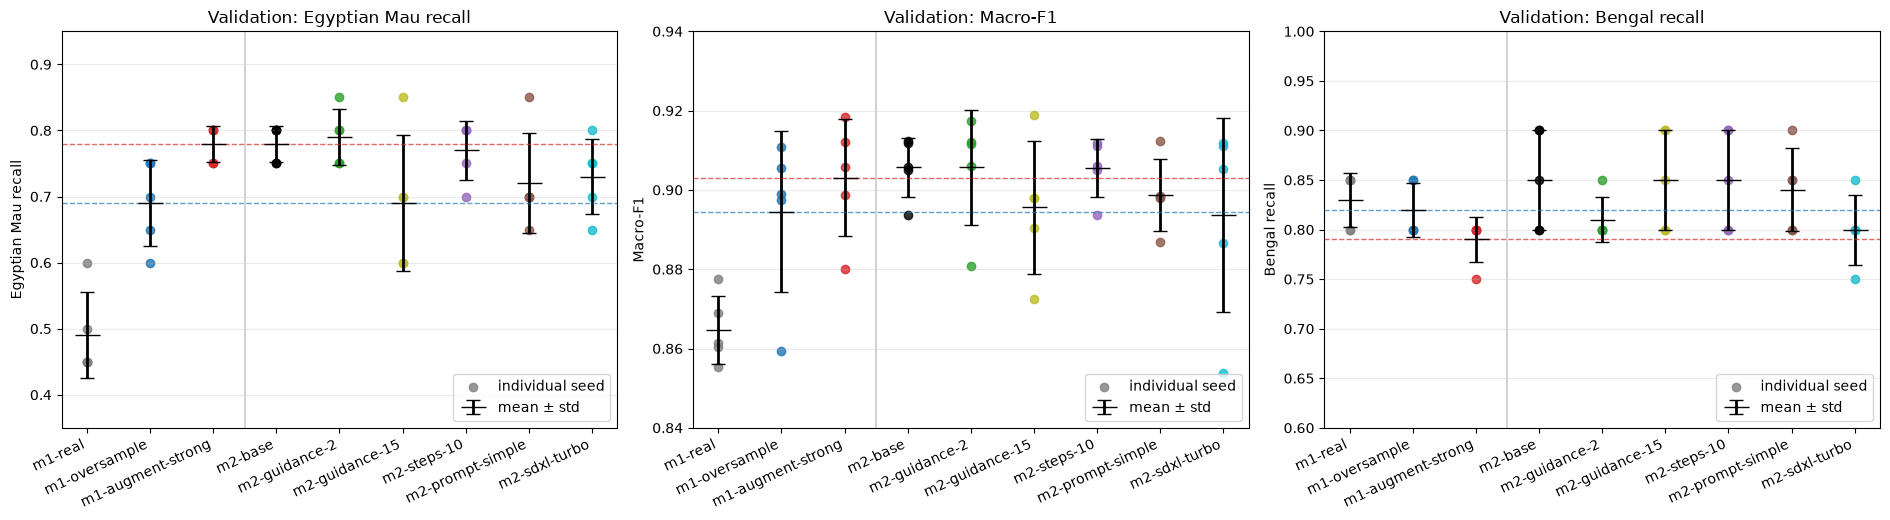

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.3))
for ax, (metric, label, ylim) in zip(axes, [("egyptian_mau_recall", "Egyptian Mau recall", (0.35, 0.95)),
                                            ("macro_f1", "Macro-F1", (0.84, 0.94)),
                                            ("bengal_recall", "Bengal recall", (0.6, 1.0))]):
    plot_metric(results, metric, label, f"Validation: {label}", RUN_NAMES, ax, ylim)
    for ref in ["m1-oversample", "m1-augment-strong"]:
        ax.axhline(results.loc[results["run"] == ref, metric].mean(), color=COLORS[ref], ls="--", lw=1, alpha=0.7)
    ax.axvline(len(BASELINES) - 0.5, color="lightgray")
fig.tight_layout()
save(fig, "meeting2-validation-recall-f1.png")

#### Each setting on its own axis

The comparisons the course asks for: guidance (2, 7.5, 15), steps (10, 30), prompt (one simple vs four varied) and model. `m2-base` is the middle point of every comparison.

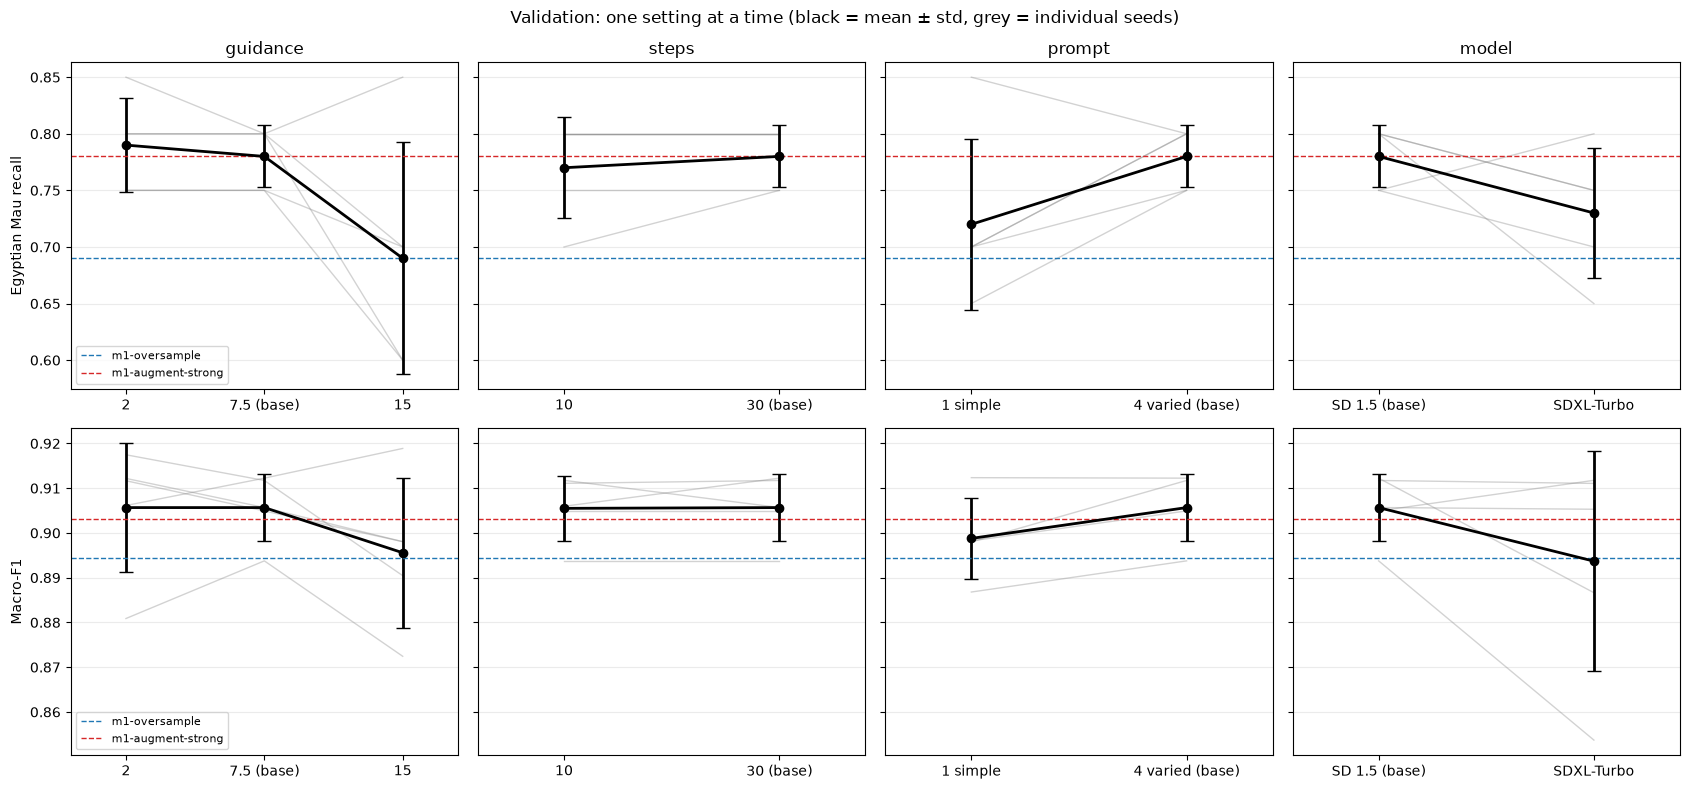

In [36]:
SWEEPS = [  # (title, x tick labels, runs)
    ("guidance", ["2", "7.5 (base)", "15"], ["m2-guidance-2", "m2-base", "m2-guidance-15"]),
    ("steps", ["10", "30 (base)"], ["m2-steps-10", "m2-base"]),
    ("prompt", ["1 simple", "4 varied (base)"], ["m2-prompt-simple", "m2-base"]),
    ("model", ["SD 1.5 (base)", "SDXL-Turbo"], ["m2-base", "m2-sdxl-turbo"]),
]
fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharey="row")
for col, (title, ticks, runs) in enumerate(SWEEPS):
    for row, (metric, label) in enumerate([("egyptian_mau_recall", "Egyptian Mau recall"), ("macro_f1", "Macro-F1")]):
        ax = axes[row, col]
        wide = results[results["run"].isin(runs)].pivot(index="seed", columns="run", values=metric)[runs]
        for k, values in wide.iterrows():  # one grey line per seed: the paired view
            ax.plot(range(len(runs)), values, color="gray", alpha=0.35, lw=1)
        ax.errorbar(range(len(runs)), wide.mean(), yerr=wide.std(ddof=1), color="black", marker="o", capsize=5, lw=2)
        for ref in ["m1-oversample", "m1-augment-strong"]:
            ax.axhline(results.loc[results["run"] == ref, metric].mean(), color=COLORS[ref], ls="--", lw=1,
                       label=ref if col == 0 else None)
        ax.set_xticks(range(len(runs)), ticks)
        ax.set_xlim(-0.4, len(runs) - 0.6)
        ax.grid(axis="y", alpha=0.25)
        if row == 0:
            ax.set_title(f"{title}")
        if col == 0:
            ax.set_ylabel(label)
            ax.legend(loc="lower left", fontsize=8)
fig.suptitle("Validation: one setting at a time (black = mean ± std, grey = individual seeds)")
fig.tight_layout()
save(fig, "meeting2-validation-sweeps.png")

#### Seed-by-seed differences and significance

Seed *k* of every run starts from the same pretrained weights and the same seed, so runs can be compared in pairs (as in Meeting 1). With 5 seeds the smallest possible p is 2/32 = 0.0625.

**Does each setting change anything vs the base pool?**

In [37]:
vs_base = paired_tests(results, [(r, "m2-base") for r in POOL_RUNS[1:]])
rival_rows = vs_base.index[vs_base["comparison"] == f"{RIVAL} − {PICK}"]
highlight(vs_base, cells=cells_of(rival_rows, vs_base.columns),
          key=cells_of(rival_rows, ["seeds better", "seeds equal", "p (sign-flip)"]))

,metric,comparison,mean diff,seeds better,seeds equal,seeds worse,p (sign-flip)
0,egyptian_mau_recall,m2-guidance-2 − m2-base,0.010,1,4,0,1.000
1,egyptian_mau_recall,m2-guidance-15 − m2-base,-0.090,1,0,4,0.188
2,egyptian_mau_recall,m2-steps-10 − m2-base,-0.010,0,4,1,1.000
3,egyptian_mau_recall,m2-prompt-simple − m2-base,-0.060,1,0,4,0.188
4,egyptian_mau_recall,m2-sdxl-turbo − m2-base,-0.050,1,0,4,0.312
5,macro_f1,m2-guidance-2 − m2-base,0.000,3,0,2,1.000
6,macro_f1,m2-guidance-15 − m2-base,-0.010,1,0,4,0.125
7,macro_f1,m2-steps-10 − m2-base,-0.000,1,2,2,0.750
8,macro_f1,m2-prompt-simple − m2-base,-0.007,1,0,4,0.125
9,macro_f1,m2-sdxl-turbo − m2-base,-0.012,1,0,4,0.312


**Does each pool beat the Meeting 1 bars?**

In [38]:
tests = paired_tests(results, [(r, ref) for ref in ["m1-oversample", "m1-augment-strong"] for r in POOL_RUNS],
                     metrics=("egyptian_mau_recall",))
pick_rows = tests.index[tests["comparison"].str.startswith(f"{PICK} −")]
highlight(tests, cells=cells_of(pick_rows, tests.columns),
          key=cells_of(pick_rows[:1], ["seeds better", "p (sign-flip)"]))  # base beats oversample on every seed

,metric,comparison,mean diff,seeds better,seeds equal,seeds worse,p (sign-flip)
0,egyptian_mau_recall,m2-base − m1-oversample,0.090,5,0,0,0.062
1,egyptian_mau_recall,m2-guidance-2 − m1-oversample,0.100,5,0,0,0.062
2,egyptian_mau_recall,m2-guidance-15 − m1-oversample,-0.000,1,2,2,1.000
3,egyptian_mau_recall,m2-steps-10 − m1-oversample,0.080,5,0,0,0.062
4,egyptian_mau_recall,m2-prompt-simple − m1-oversample,0.030,2,2,1,0.500
5,egyptian_mau_recall,m2-sdxl-turbo − m1-oversample,0.040,3,2,0,0.250
6,egyptian_mau_recall,m2-base − m1-augment-strong,0.000,1,3,1,1.000
7,egyptian_mau_recall,m2-guidance-2 − m1-augment-strong,0.010,2,2,1,1.000
8,egyptian_mau_recall,m2-guidance-15 − m1-augment-strong,-0.090,1,0,4,0.125
9,egyptian_mau_recall,m2-steps-10 − m1-augment-strong,-0.010,1,2,2,1.000


#### Recall of every breed

Do the generated Maus cost the other breeds anything? Mean over 5 seeds; Bengal, the closest look-alike, is the one to watch.

In [39]:
breed_recall = load_breed_recall("results.json")
breed_table = breed_recall.groupby(["breed", "run"])["recall"].mean().unstack()[RUN_NAMES]
highlight(breed_table, cells=cells_of(["Bengal"], RUN_NAMES), key=[("Bengal", PICK), ("Bengal", RIVAL)], precision=2)

run,m1-real,m1-oversample,m1-augment-strong,m2-base,m2-guidance-2,m2-guidance-15,m2-steps-10,m2-prompt-simple,m2-sdxl-turbo
breed,,,,,,,,,
Abyssinian,0.96,0.97,0.97,0.96,0.95,0.97,0.97,0.97,0.96
Bengal,0.83,0.82,0.79,0.85,0.81,0.85,0.85,0.84,0.80
Birman,0.91,0.90,0.91,0.89,0.93,0.89,0.89,0.89,0.90
Bombay,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
Egyptian Mau,0.49,0.69,0.78,0.78,0.79,0.69,0.77,0.72,0.73
Ragdoll,0.87,0.87,0.86,0.85,0.86,0.85,0.86,0.86,0.85
Russian Blue,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
Siamese,0.91,0.92,0.92,0.92,0.91,0.93,0.91,0.92,0.92


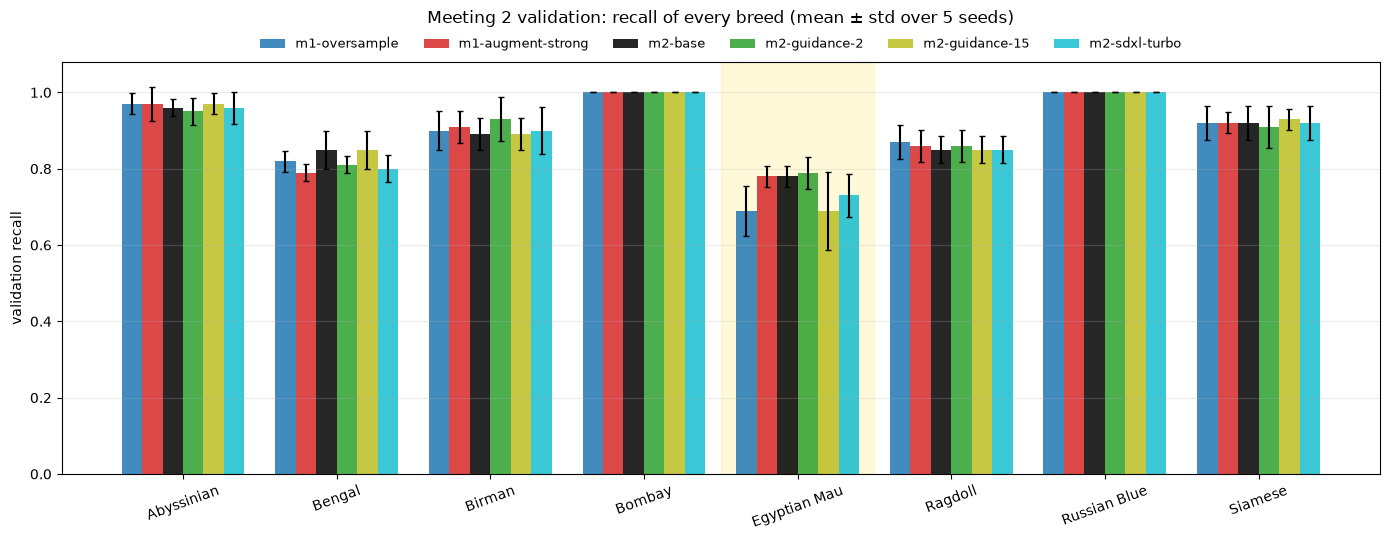

In [40]:
SHOWN_RUNS = ["m1-oversample", "m1-augment-strong", "m2-base", "m2-guidance-2", "m2-guidance-15", "m2-sdxl-turbo"]
breeds = list(dict.fromkeys(breed_recall["breed"]))
fig, ax = plt.subplots(figsize=(14, 5.5))
width = 0.8 / len(SHOWN_RUNS)
for r, run_name in enumerate(SHOWN_RUNS):
    sub = breed_recall[breed_recall["run"] == run_name]
    stats = sub.groupby("breed")["recall"].agg(["mean", "std"]).reindex(breeds)
    x = np.arange(len(breeds)) + (r - (len(SHOWN_RUNS) - 1) / 2) * width
    ax.bar(x, stats["mean"], width, yerr=stats["std"], capsize=2, color=COLORS[run_name], alpha=0.85, label=run_name)
mau = breeds.index(TARGET)
ax.axvspan(mau - 0.5, mau + 0.5, color="gold", alpha=0.15, zorder=0)
ax.set_xticks(range(len(breeds)), breeds, rotation=20)
ax.set_ylim(0, 1.08)
ax.set_ylabel("validation recall")
ax.set_title("Meeting 2 validation: recall of every breed (mean ± std over 5 seeds)", pad=28)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(SHOWN_RUNS), frameon=False, fontsize=9)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
save(fig, "meeting2-validation-per-breed-recall.png")

#### Where the Egyptian Mau errors go

Raw counts from the confusion matrices summed over the 5 seeds: what the 100 validation Mau predictions per run were classified as, and which other breeds were wrongly called Mau (out of 100 per breed).

In [41]:
mau_errors = mau_error_table(RUN_NAMES)
# Russian Blue row: the one place where guidance 2 does better than base
highlight(mau_errors["Mau predicted as"], cells=[("Russian Blue", PICK)], key=[("Russian Blue", RIVAL)], precision=0)

,m1-real,m1-oversample,m1-augment-strong,m2-base,m2-guidance-2,m2-guidance-15,m2-steps-10,m2-prompt-simple,m2-sdxl-turbo
breed,,,,,,,,,
Abyssinian,10,10,9,5,5,7,5,9,8
Bengal,27,13,8,10,15,12,11,12,11
Birman,0,0,0,0,0,0,0,0,0
Bombay,0,0,0,0,0,0,0,0,0
Egyptian Mau,49,69,78,78,79,69,77,72,73
Ragdoll,3,0,0,0,0,0,0,0,0
Russian Blue,11,8,5,7,1,12,7,7,8
Siamese,0,0,0,0,0,0,0,0,0


In [42]:
# Bengal row: Bengals wrongly called Mau, the cost Meeting 1 said to watch
highlight(mau_errors["predicted as Mau"], cells=[("Bengal", RIVAL), ("Bengal", "m1-augment-strong"), ("Bengal", "m1-oversample")],
          key=[("Bengal", PICK)], precision=0)

,m1-real,m1-oversample,m1-augment-strong,m2-base,m2-guidance-2,m2-guidance-15,m2-steps-10,m2-prompt-simple,m2-sdxl-turbo
breed,,,,,,,,,
Abyssinian,0,0,0,0,0,0,0,0,0
Bengal,2,6,9,2,6,2,2,3,7
Birman,0,0,0,0,0,0,0,0,0
Bombay,0,0,0,0,0,0,0,0,0
Egyptian Mau,49,69,78,78,79,69,77,72,73
Ragdoll,0,0,0,0,0,0,0,0,0
Russian Blue,0,0,0,0,0,0,0,0,0
Siamese,0,0,0,0,0,0,0,0,0


#### Confusion matrices

The base pool, the best and worst SD 1.5 settings, SDXL-Turbo, and the strong-augment baseline. Summed over 5 seeds, row-normalised.

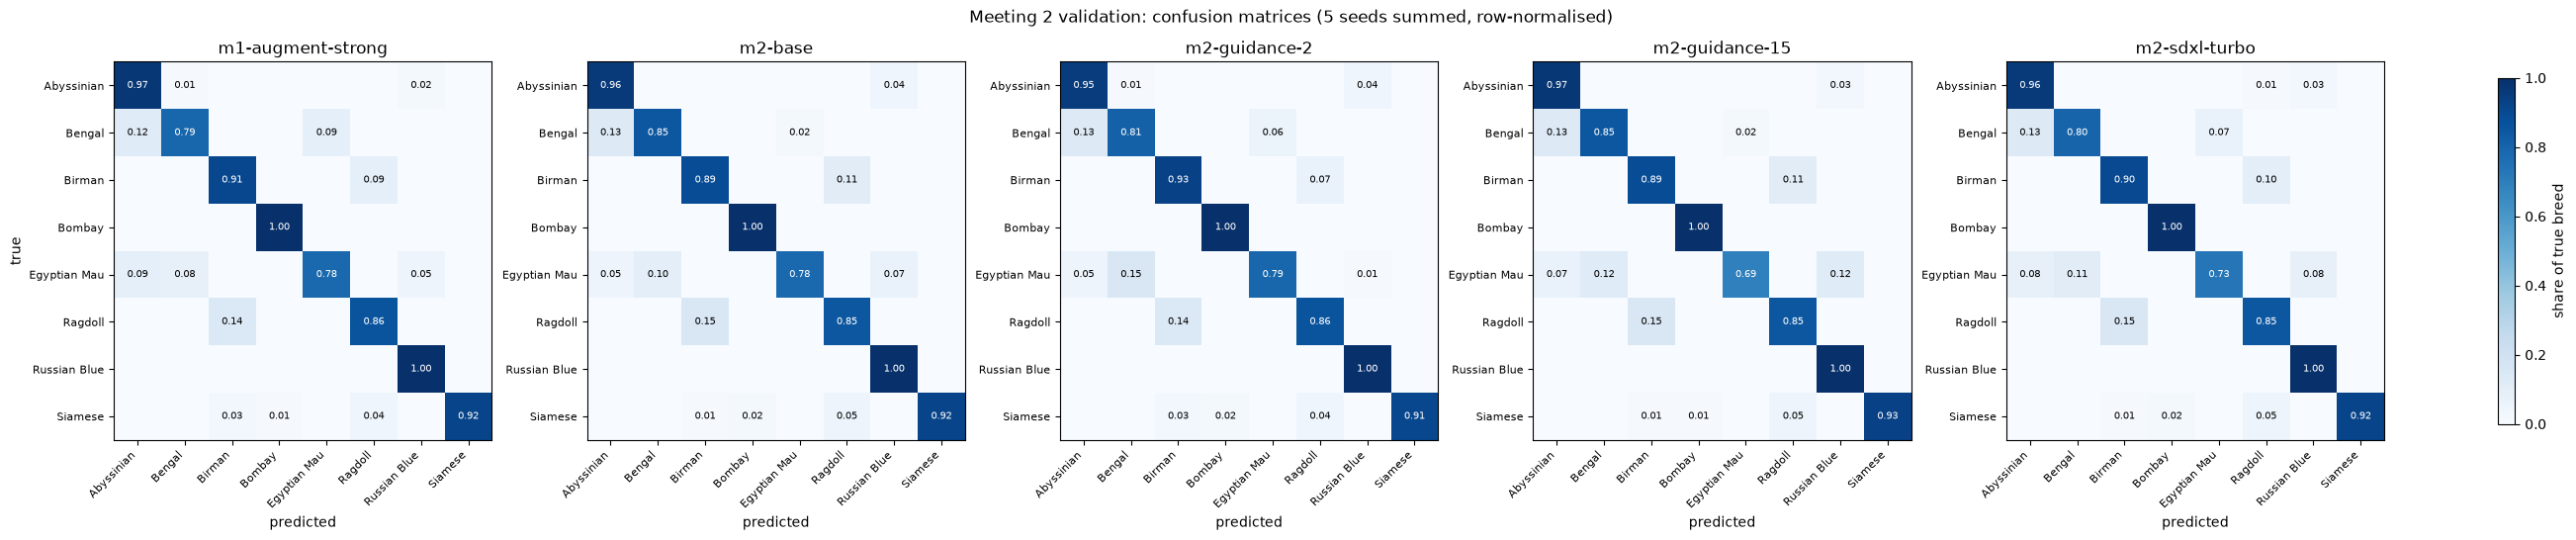

In [43]:
CM_RUNS = ["m1-augment-strong", "m2-base", "m2-guidance-2", "m2-guidance-15", "m2-sdxl-turbo"]
fig, axes = plt.subplots(1, len(CM_RUNS), figsize=(5.2 * len(CM_RUNS), 5.4), constrained_layout=True)
for ax, run_name in zip(axes, CM_RUNS):
    matrix, names = summed_confusion(run_name)
    norm = matrix / matrix.sum(axis=1, keepdims=True)
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(names)):
        for j in range(len(names)):
            if matrix[i, j]:
                ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if norm[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(names)), names, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(names)), names, fontsize=8)
    ax.set_xlabel("predicted")
    ax.set_title(run_name)
axes[0].set_ylabel("true")
fig.colorbar(im, ax=axes, shrink=0.8, label="share of true breed")
fig.suptitle("Meeting 2 validation: confusion matrices (5 seeds summed, row-normalised)")
save(fig, "meeting2-validation-confusion.png")

#### Which validation Maus are missed

Each of the 20 validation Maus is judged by 5 models per run. The table counts in how many of the 5 it was **not** recognised, for the photos missed at least once by any run. Meeting 1's hard photos were #15, #155, #131 (never recognised), #152 and #171 (recovered only by the strong recipe).

In [44]:
rows = []
for run_name in RUN_NAMES:
    for k in range(5):
        with open(RUNS_DIR / run_name / f"seed-{k}" / "predictions.csv") as stream:
            for r in csv.DictReader(stream):
                if r["breed"] == TARGET:
                    rows.append({"photo": r["image"], "run": run_name, "predicted": r["predicted"]})
mau_preds = pd.DataFrame(rows)
wrong = mau_preds[mau_preds["predicted"] != TARGET]
missed = wrong.groupby(["photo", "run"]).size().unstack(fill_value=0).reindex(columns=RUN_NAMES, fill_value=0)
m2_wrong = wrong[wrong["run"].isin(POOL_RUNS)]
missed["m2 total of 30"] = missed[POOL_RUNS].sum(axis=1)
missed["m2 mistaken for"] = m2_wrong.groupby("photo")["predicted"].agg(lambda s: ", ".join(f"{b} {n}" for b, n in s.value_counts().items()))
missed = missed.sort_values(["m2 total of 30", "m1-augment-strong"], ascending=False)
missed.index = missed.index.str.replace("Egyptian_Mau_", "#")
print(f"{20 - (missed['m2 total of 30'] > 0).sum()} of 20 validation Maus are recognised by all 30 Meeting 2 models; "
      f"{(missed['m2 total of 30'] == 30).sum()} are missed by all 30.")
missed.fillna("–")

9 of 20 validation Maus are recognised by all 30 Meeting 2 models; 2 are missed by all 30.


run,m1-real,m1-oversample,m1-augment-strong,m2-base,m2-guidance-2,m2-guidance-15,m2-steps-10,m2-prompt-simple,m2-sdxl-turbo,m2 total of 30,m2 mistaken for
photo,,,,,,,,,,,
#131,5,5,5,5,5,5,5,5,5,30,Bengal 30
#155,5,5,5,5,5,5,5,5,5,30,Abyssinian 30
#171,5,5,1,5,5,4,5,5,5,29,Bengal 29
#152,5,3,4,5,1,5,5,4,5,25,Russian Blue 25
#15,5,5,5,0,0,2,0,4,4,10,"Abyssinian 9, Russian Blue 1"
#148,5,3,2,0,0,4,1,3,1,9,"Bengal 6, Russian Blue 3"
#11,5,3,0,1,0,4,1,2,1,9,Russian Blue 9
#157,5,1,0,1,0,2,1,0,0,4,Russian Blue 4
#110,4,1,0,0,3,0,0,0,0,3,Bengal 3


## 5. Picking the pool to test, and the test results

### 5.1 Pick

**One** pool run is tested, chosen on validation only (reasoning in section 6.1). To test: set `TEST_POOL` below, set the **same** value as `POOL_RUN` in [colab/m2_test.ipynb](../colab/m2_test.ipynb), run that notebook in Colab, then `git pull` here and re-run from this cell. The cell checks that the two notebooks agree. Once tested, don't change the choice.

In [45]:
TEST_POOL = "m2-base"  # ← the pool run kept after validation (section 6.1); never change after testing

assert TEST_POOL in POOL_RUNS, f"pick one of {POOL_RUNS}, got {TEST_POOL!r}"
TEST_RUNS = BASELINES + [TEST_POOL]

pick_table = summarize(results, POOL_RUNS)[["recall_mean", "recall_std", "recall_min", "macro_f1_mean", "macro_f1_std", "bengal_recall"]]
pick_table["Bengals called Mau"] = mau_errors["predicted as Mau"].loc["Bengal", POOL_RUNS]
pick_table["picked"] = np.where(pick_table.index == TEST_POOL, "✅", "")
display(highlight(pick_table, cells=cells_of([TEST_POOL], pick_table.columns),
                  key=cells_of([TEST_POOL, RIVAL], ["recall_mean", "bengal_recall", "Bengals called Mau"])))

# the Colab test notebook must test the same run
colab_src = "".join("".join(c["source"]) for c in json.loads(Path("colab/m2_test.ipynb").read_text())["cells"])
colab_pick = next((r for r in POOL_RUNS if f'POOL_RUN = "{r}"' in colab_src), None)
if colab_pick != TEST_POOL:
    print(f"⚠ colab/m2_test.ipynb tests POOL_RUN = {colab_pick!r}, not {TEST_POOL!r}: make them match.")

status = {n: (RUNS_DIR / n / "test-results.json").exists() for n in TEST_RUNS}
HAVE_TEST = all(status.values())
for n, done in status.items():
    print(f"{'✅' if done else '⬜'} {n}: {'tested' if done else 'no test results yet'}")
if not HAVE_TEST:
    print("\nRun colab/m2_test.ipynb in Colab, then `git pull`. Section 5.2 is skipped until then.")

,recall_mean,recall_std,recall_min,macro_f1_mean,macro_f1_std,bengal_recall,Bengals called Mau,picked
run,,,,,,,,
m2-base,0.780,0.027,0.750,0.906,0.007,0.850,2,✅
m2-guidance-2,0.790,0.042,0.750,0.906,0.014,0.810,6,
m2-guidance-15,0.690,0.102,0.600,0.896,0.017,0.850,2,
m2-steps-10,0.770,0.045,0.700,0.905,0.007,0.850,2,
m2-prompt-simple,0.720,0.076,0.650,0.899,0.009,0.840,3,
m2-sdxl-turbo,0.730,0.057,0.650,0.894,0.025,0.800,7,


⚠ colab/m2_test.ipynb tests POOL_RUN = None, not 'm2-base': make them match.
✅ m1-real: tested
✅ m1-oversample: tested
✅ m1-augment-strong: tested
⬜ m2-base: no test results yet

Run colab/m2_test.ipynb in Colab, then `git pull`. Section 5.2 is skipped until then.


### 5.2 Test results

Evaluated once (240 test photos, 30 per breed, so one Mau photo = 0.033 recall), next to the three Meeting 1 baselines.

#### Per-seed results and summary

In [46]:
if HAVE_TEST:
    test_results = load_runs("test-results.json", TEST_RUNS)
    display(test_results.pivot(index="seed", columns="run", values=["egyptian_mau_recall", "macro_f1"]).reindex(
        columns=pd.MultiIndex.from_product([["egyptian_mau_recall", "macro_f1"], TEST_RUNS])).round(3))
    test_summary = summarize(test_results, TEST_RUNS)
    display(test_summary)
else:
    print("Skipped: no test results yet.")

Skipped: no test results yet.


#### Validation vs test

In [47]:
if HAVE_TEST:
    val_results = load_runs("results.json", TEST_RUNS)
    val_summary = summarize(val_results, TEST_RUNS)
    display(pd.DataFrame({
        "val recall": val_summary["recall_mean"], "test recall": test_summary["recall_mean"],
        "val macro-F1": val_summary["macro_f1_mean"], "test macro-F1": test_summary["macro_f1_mean"],
        "val Bengal": val_summary["bengal_recall"], "test Bengal": test_summary["bengal_recall"],
    }))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, (metric, label) in zip(axes, [("egyptian_mau_recall", "Egyptian Mau recall"), ("macro_f1", "Macro-F1")]):
        for offset, (name, df, marker) in zip([-0.12, 0.12], [("validation", val_results, "o"), ("test", test_results, "s")]):
            for position, run_name in enumerate(TEST_RUNS):
                values = df.loc[df["run"] == run_name, metric]
                ax.errorbar(position + offset, values.mean(), yerr=values.std(ddof=1), fmt=marker,
                            color=COLORS[run_name], mfc="white" if name == "test" else COLORS[run_name],
                            capsize=4, markersize=8, label=name if position == 0 else None)
        ax.set_xticks(range(len(TEST_RUNS)), TEST_RUNS, rotation=10)
        ax.set_ylabel(label)
        ax.set_title(f"{label}: validation (filled) vs test (open), mean ± std")
        ax.grid(axis="y", alpha=0.25)
        ax.legend()
    fig.tight_layout()
    save(fig, "meeting2-val-vs-test.png")
else:
    print("Skipped: no test results yet.")

Skipped: no test results yet.


#### Seed-by-seed significance and errors on test

In [48]:
if HAVE_TEST:
    display(paired_tests(test_results, [(TEST_POOL, b) for b in BASELINES]))
    display(mau_error_table([b for b in TEST_RUNS]).rename_axis(None))
else:
    print("Skipped: no test results yet.")

Skipped: no test results yet.


## 6. Interpretation

### 6.1 Validation (written before the test set is evaluated)

All six pools were generated and trained in Colab on a Tesla T4 (`cuda`): about 5 s per SD 1.5 image and 1.2 s per SDXL-Turbo image, 35 s per training seed.

| Run | Changed | Mau recall, seeds 0–4 | Mau recall mean ± std | Macro-F1 | Bengals called Mau (of 100) |
| --- | --- | --- | ---: | ---: | ---: |
| `m1-oversample` | Meeting 1 | 0.70, 0.60, 0.65, 0.75, 0.75 | 0.69 ± 0.07 | 0.894 | 6 |
| `m1-augment-strong` | Meeting 1 | 0.80, 0.75, 0.75, 0.80, 0.80 | 0.78 ± 0.03 | 0.903 | 9 |
| **`m2-base`** | – | 0.75, 0.80, 0.75, 0.80, 0.80 | **0.78 ± 0.03** | **0.906** | **2** |
| `m2-guidance-2` | guidance 2 | 0.75, 0.80, 0.75, 0.80, 0.85 | 0.79 ± 0.04 | 0.906 | 6 |
| `m2-guidance-15` | guidance 15 | 0.70, 0.60, 0.60, 0.70, 0.85 | 0.69 ± 0.10 | 0.896 | 2 |
| `m2-steps-10` | 10 steps | 0.75, 0.80, 0.70, 0.80, 0.80 | 0.77 ± 0.05 | 0.905 | 2 |
| `m2-prompt-simple` | 1 prompt | 0.70, 0.70, 0.65, 0.70, 0.85 | 0.72 ± 0.08 | 0.899 | 3 |
| `m2-sdxl-turbo` | model | 0.80, 0.65, 0.70, 0.75, 0.75 | 0.73 ± 0.06 | 0.894 | 7 |

**Generated images add something beyond balancing, against my expectation.** I expected text-to-image to be the riskiest method and "at best a small gain over oversampling". Instead the base pool beats oversampling on **every** seed (+0.09, p = 0.0625, the minimum), and so do guidance 2 (+0.10) and 10 steps (+0.08). The 55 generated images do what copies of the 15 photos can't. Macro-F1 rises with them (0.906 vs 0.894), so the gain isn't paid for by the other breeds.

**The best pools match strong augmentation, but don't beat it.** `m2-base` and `m1-augment-strong` have the same mean recall (0.78), with seed differences of −0.05, +0.05, 0, 0, 0 (p = 1.0). So, on validation, text-to-image is as good as the best real-data method, not better.

**But it gets there by a different route, and at a lower cost.** The difference is in where the errors go:

- **Bengals called "Mau" drop to 2 of 100** with the base pool, against 6 for oversampling and 9 for strong augmentation, and Bengal recall is 0.85, the highest of all balanced runs (shared with 10 steps and guidance 15; strong: 0.79). This is the cost Meeting 1 flagged as "the number to watch", and the base pool doesn't pay it.
- **Maus called Abyssinian halve** (9 → 5 of 100).
- The **hard photos change**. #15, the small cat far away on a bed that **none of the three Meeting 1 baselines ever recognised** (0 of 15 models; 1 of 20 in Meeting 1 counting mild augment), is recognised by all 5 base models, all 5 guidance-2 models and all 5 steps-10 models; #148 too. In exchange, #171 (on a wire cage), which only the strong recipe recovered (4 of 5), is lost again (0 of 5). #131 and #155 stay wrong in all 30 Meeting 2 models.

**A plausible reason: the SD 1.5 images add scenes and framings, not breed detail.** Section 2.5 shows SD 1.5 can't draw a Mau's spots: the cats are grey tabbies and bicolours. What the prompts *do* control is the scene: cats small in a room (prompt 4, "walking across a wooden floor", gives exactly the distant-cat framing of #15), cats lying on sofas, close-ups. That is the kind of variety the 15 training photos (side-on, whole cat, plain backdrop) lack. And because the generated cats are not spotted, they don't teach "spotted ⇒ Mau", which is what would pull Bengals over. This fits the numbers, but it is not isolated by these runs (see 6.4).

**What each setting does** (all compared seed by seed with `m2-base`; none of the differences reaches p < 0.1 with 5 seeds):

- **Guidance.** 2 ≈ 7.5 > 15. Guidance 2 has the same recall (+0.01, one seed better, four equal) and the fewest Maus called Russian Blue of any run (1 of 100, vs 7), but more Bengals called Mau (6 vs 2) and Bengal recall 0.81 instead of 0.85; its pool is more varied and also has more failures (no cat, tiny cat). **Guidance 15 is clearly worse**: recall falls to the oversampling level (0.69, worse than base on 4 of 5 seeds) with by far the widest spread (0.60–0.85), and Maus called Russian Blue rise to 12. Its images keep the base compositions but with harsh, saturated colours, a "generated look" that may cost the classifier more than it teaches.
- **Steps.** 10 ≈ 30 (−0.01; 4 seeds equal). The images are nearly identical (2.4), so this is the expected null result: DPM-Solver++ doesn't need 30 steps. 10 steps would save 60% of generation time at no measurable cost.
- **Prompt.** **One simple prompt is worse** (0.72, −0.06, worse on 4 of 5 seeds; p = 0.19): the pool has one pose and one kind of scene. It loses #15 again (missed 4 of 5), which supports the idea that the varied scenes are what helped.
- **Model.** **SDXL-Turbo, the most Mau-looking pool, is worse** than SD 1.5 (0.73, −0.05, worse on 4 of 5 seeds; p = 0.31), with the lowest macro-F1 of the pools (0.894) and more Bengals called Mau (7 vs 2). This is the "plausible-looking cat is not automatically a useful training example" case, in two ways: its spotted, rosetted, stripy-legged cats sit between Mau and Bengal and move the boundary towards Bengal; and its pool repeats three compositions, so it adds little of the scene variety the base pool adds. It also changes four things at once (model, steps, guidance, scheduler; 1.3), so which of them matters can't be separated.

**Which pool to take forward.** The candidates are `m2-base` and `m2-guidance-2`; every other pool is worse than base on at least 4 of 5 seeds.

- for **`m2-guidance-2`**: the highest mean recall (0.79), from one seed (0.85 vs 0.80); fewest Maus lost to Russian Blue.
- for **`m2-base`**: the same recall within one photo on one seed (p = 1.0), the same macro-F1 (0.906) with half the spread (± 0.007 vs ± 0.014), the lowest recall spread of any run (± 0.03), and the clearest advantage over Meeting 1: **2 Bengals called Mau instead of 6**, Bengal recall 0.85 instead of 0.81. It is also the reference every setting was compared against, not the best of six noisy means, so its validation value is less inflated by the choice itself.

> **Decision:** I take forward **`m2-base`**. On the main metric it is tied with guidance 2 (0.78 vs 0.79, one photo on one seed). On everything else it is as good or better: the same macro-F1 with less spread, and only 2 Bengals per 100 called Mau, the visible cost of every gain in Meeting 1. Its four prompts carry into Meeting 3. The number to check on test is whether it holds strong augmentation's recall (0.73) with less Bengal cost; whether it beats strong augmentation is not expected, since it doesn't on validation either.

### 6.2 Test

*To be written after [colab/m2_test.ipynb](../colab/m2_test.ipynb) has tested the pool chosen in 6.1 and section 5.2 shows the results.* What to check, set before the test:

- Does `m2-base` keep its lead over oversampling on test (validation: +0.09, every seed)?
- Does it hold strong augmentation's test recall (0.73 ± 0.03)? On validation they were tied.
- Does the lower Bengal cost carry over (validation: 2 Bengals called Mau per 100, vs 9 for strong)? On test, strong augmentation called 4 of 150 Bengals Mau.
- The validation recall of the chosen pool is likely to fall somewhat on test, as strong augmentation's did (0.78 → 0.73), because the choice was made on the same 20 validation Maus.

### 6.3 Conclusion

Meeting 2 asked whether Mau images generated from text help more than copies of the 15 photos, and which settings make them useful. On validation (test pending, 6.2):

Against the expectations in 1.2: text-to-image is not the riskiest method; with the right settings it is one of the best (expectation 1 refuted). Guidance 15 harms, as expected, though through harsh colours rather than visibly narrower images; guidance 2 does not hurt (expectation 2 half right). 10 steps changes nothing (expectation 3 refuted: no visible blur, no loss). One simple prompt is narrower and worse, as expected (4). SDXL-Turbo is polished and repetitive, as expected (5), and worse, which I hadn't predicted.

1. **Generated images beat copies.** The base pool beats oversampling on every seed (+0.09) and ties with strong augmentation (0.78), with the highest macro-F1 so far (0.906).
2. **Its gain is cheaper.** Only 2 of 100 Bengals are called Mau (strong augmentation: 9). It recognises #15, a Mau none of the Meeting 1 baselines ever got.
3. **"Looks like a Mau" is not "useful".** SD 1.5 draws grey tabbies and bicolour cats, not Maus, and works best; SDXL-Turbo draws convincing spotted cats and works worse, with more Bengals called Mau. What seems to matter is varied scenes and framings, without pulling the look of the cat towards Bengal.
4. **Narrower or harsher pools hurt.** One simple prompt and SDXL-Turbo make less varied pools, guidance 15 makes harsher images; all three lose 0.05–0.09 recall. Steps don't matter above 10.
5. **What is still not solved.** #131 (curled up, seen from above) and #155 (bronze portrait) are missed by all 30 Meeting 2 models, as by all of Meeting 1; and no SD 1.5 image is bronze. These are what Meeting 3, which starts from the real Mau photos, can try.

### 6.4 Limitations

- **Few seeds, one photo = 0.05:** no setting differs from the base pool with p < 0.1; the small differences (guidance 2, 10 steps) are within one or two photos. The conclusions about settings rest on consistent direction over 4–5 seeds, not on significance.
- **One pool per setting, one set of prompts.** Each setting was tried once, with my four prompts. A different prompt set could change the ranking of the settings; the simple-prompt result says the prompt matters at least as much as guidance.
- **SDXL-Turbo changes several things.** Model, steps, guidance, scheduler and the (unused) negative prompt change together, so "SDXL-Turbo is worse" can't be pinned on one of them.
- **The failure types come from 24 of 110 images per pool**, by eye. I didn't count how many images are Mau-like, so "SD 1.5 doesn't draw Maus" is a qualitative judgement.
- **Why the base pool works is inferred, not shown.** "Scene variety without Bengal-like spots" fits the confusion counts and the recovered photos (#15), but it would need a test, e.g. a pool with the base prompts but plain backdrops, or a measure of how close the generated images are to Bengal in the classifier's feature space.
- **Same images, different settings.** All SD 1.5 pools start from the same noise per image number, and every seed draws the same image numbers from each pool (2.6; the pools with safety-blocked images draw slightly differently). This makes the comparisons paired and fair, but it also means each comparison rests on the same 55 noise seeds per training seed.
- **Choosing on validation.** The pick uses the same 20 validation Maus that show the gain, so the test value (6.2) is the honest estimate. Looking at the hard validation photos (like #15) to explain results is fine; designing the Meeting 3 prompts around them would not be.